# End-to-End DBSCAN Clustering & Outlier Detection (No PCA)
This notebook implements **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** directly across all **8 original features** of the California Housing dataset (`20,640` records) without any dimensionality reduction (no PCA).

### What This Pipeline Demonstrates:
1. **Dataset Loading & Pre-Clustering EDA**: Inspecting raw distributions, scale differences, and extreme anomalies before training.
2. **Feature Standardization & Optimal $\varepsilon$ Discovery**: Scaling all 8 features equally and finding the mathematical elbow point using the $k$-Distance graph.
3. **Multi-Feature DBSCAN Clustering**: Grouping all 8 features simultaneously into dense spatial/economic clusters (`Cluster >= 0`) while isolating anomalies as Noise (`Cluster = -1`).
4. **Clustering Evaluation & Accuracy Scores**: Computing internal validation scores (Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Score) and comparing how DBSCAN handles single vs. multiple cluster regimes across $\varepsilon$ thresholds.
5. **Post-Clustering EDA & Direct Feature Visualizations**: Examining how outliers are captured directly in the original feature space (Geospatial coordinates, Median Income, Average Rooms, Population, and House Value).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set clean visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

---
### 1. Load Dataset (20,640 Records)

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print(f"Total Records : {df.shape[0]:,}")
print(f"Total Columns : {df.shape[1]}")
df.head()

Total Records : 20,640
Total Columns : 9


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


---
### 2. Pre-Clustering EDA (Before DBSCAN Training)

In [3]:
print("[PRE-EDA] Summary Statistics (Raw Original Features):")
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))

print("\n[PRE-EDA] Missing Values Check:")
missing_count = df.isnull().sum().sum()
print(f"Total Missing Values: {missing_count}")

[PRE-EDA] Summary Statistics (Raw Original Features):
               count      mean       std      min       50%        max
MedInc       20640.0     3.871     1.900    0.500     3.535     15.000
HouseAge     20640.0    28.639    12.586    1.000    29.000     52.000
AveRooms     20640.0     5.429     2.474    0.846     5.229    141.909
AveBedrms    20640.0     1.097     0.474    0.333     1.049     34.067
Population   20640.0  1425.477  1132.462    3.000  1166.000  35682.000
AveOccup     20640.0     3.071    10.386    0.692     2.818   1243.333
Latitude     20640.0    35.632     2.136   32.540    34.260     41.950
Longitude    20640.0  -119.570     2.004 -124.350  -118.490   -114.310
MedHouseVal  20640.0     2.069     1.154    0.150     1.797      5.000

[PRE-EDA] Missing Values Check:
Total Missing Values: 0


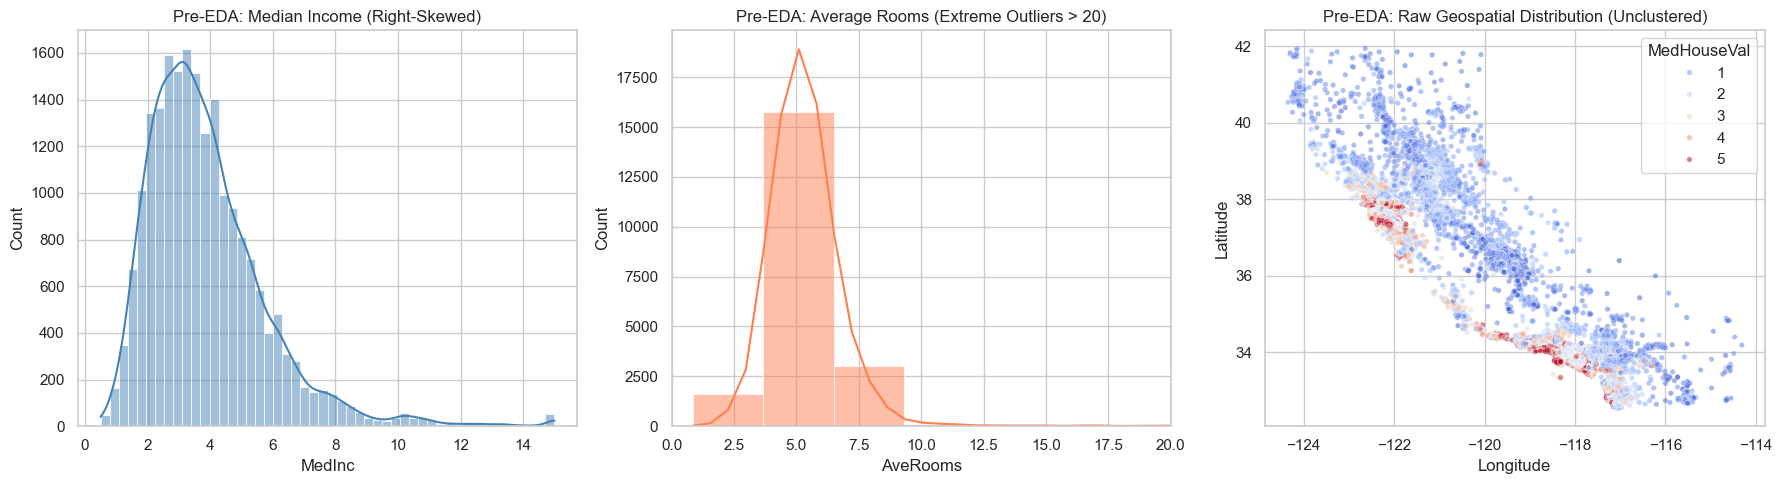

In [4]:
# Visualize Raw Distributions & Unclustered Outliers Before Training
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['MedInc'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Pre-EDA: Median Income (Right-Skewed)")

sns.histplot(df['AveRooms'], bins=50, kde=True, ax=axes[1], color='coral')
axes[1].set_xlim(0, 20)
axes[1].set_title("Pre-EDA: Average Rooms (Extreme Outliers > 20)")

sns.scatterplot(
    data=df, x='Longitude', y='Latitude', hue='MedHouseVal',
    palette='coolwarm', alpha=0.5, s=15, ax=axes[2]
)
axes[2].set_title("Pre-EDA: Raw Geospatial Distribution (Unclustered)")

plt.tight_layout()
plt.show()

---
### 3. Feature Scaling & Optimal Epsilon ($\varepsilon$) Discovery

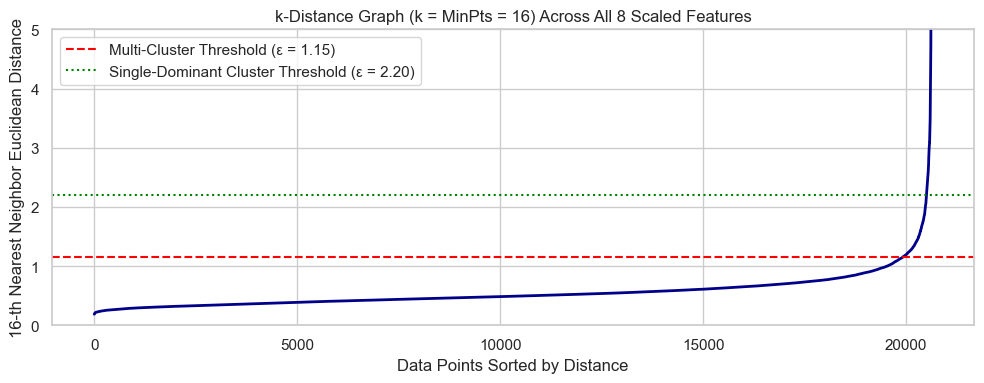

In [5]:
# All 8 features used directly (no PCA or dimensionality reduction)
features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X = df[features].values

# Standardize features so Euclidean distance treats all 8 dimensions equally
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Rule of thumb: MinPts = 2 * number of features = 16
min_pts = 2 * len(features)

# Compute distances to the k-th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=min_pts, n_jobs=-1)
distances, _ = neighbors.fit(X_scaled).kneighbors(X_scaled)
k_distances = np.sort(distances[:, min_pts - 1])

# Plot k-Distance Elbow Curve
plt.figure(figsize=(10, 4))
plt.plot(k_distances, color='darkblue', linewidth=2)
plt.axhline(y=1.15, color='red', linestyle='--', label='Multi-Cluster Threshold (ε = 1.15)')
plt.axhline(y=2.20, color='green', linestyle=':', label='Single-Dominant Cluster Threshold (ε = 2.20)')
plt.title(f"k-Distance Graph (k = MinPts = {min_pts}) Across All 8 Scaled Features")
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"{min_pts}-th Nearest Neighbor Euclidean Distance")
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()
plt.show()

---
### 4. How DBSCAN Converts All 8 Features into Single vs. Multiple Clusters & Captures Outliers

In [6]:
# Demonstrate how ε controls merging all 8 features into a single cluster vs. distinct clusters
print("COMPARING DBSCAN REGIMES ACROSS ALL 8 FEATURES (MinPts = 16):")
print("-" * 75)
for eps_test in [0.90, 1.15, 1.50, 2.20]:
    labels_test = DBSCAN(eps=eps_test, min_samples=min_pts, n_jobs=-1).fit_predict(X_scaled)
    n_clust = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_outliers = (labels_test == -1).sum()
    outlier_pct = (n_outliers / len(df)) * 100
    regime = "Single Dense Core" if n_clust == 1 else f"Multiple Clusters ({n_clust})"
    print(f"ε = {eps_test:.2f} | {regime:<25} | Outliers Captured: {n_outliers:>5,} ({outlier_pct:.2f}%)")

# Fit Final DBSCAN Model at Optimal Elbow (ε = 1.15)
eps_optimal = 1.15
dbscan = DBSCAN(eps=eps_optimal, min_samples=min_pts, metric='euclidean', n_jobs=-1)
df['Cluster'] = dbscan.fit_predict(X_scaled)
df['Point_Type'] = np.where(df['Cluster'] == -1, 'Outlier / Noise (-1)', 'Clustered Inlier (>= 0)')

COMPARING DBSCAN REGIMES ACROSS ALL 8 FEATURES (MinPts = 16):
---------------------------------------------------------------------------
ε = 0.90 | Multiple Clusters (3)     | Outliers Captured:   726 (3.52%)
ε = 1.15 | Single Dense Core         | Outliers Captured:   327 (1.58%)
ε = 1.50 | Single Dense Core         | Outliers Captured:   181 (0.88%)
ε = 2.20 | Single Dense Core         | Outliers Captured:    81 (0.39%)


---
### 5. Clustering Validation & Accuracy Metrics

In [7]:
n_clusters = len(set(df['Cluster'])) - (1 if -1 in df['Cluster'].values else 0)
n_noise = (df['Cluster'] == -1).sum()
n_inliers = len(df) - n_noise

print("=" * 65)
print(f"FINAL DBSCAN MODEL PERFORMANCE (ε = {eps_optimal}, MinPts = {min_pts})")
print("=" * 65)
print(f"Total Clusters Discovered   : {n_clusters}")
print(f"Clustered Inlier Points     : {n_inliers:,} ({n_inliers / len(df) * 100:.2f}%)")
print(f"Outliers / Noise (-1)       : {n_noise:,} ({n_noise / len(df) * 100:.2f}%)")

# Evaluate internal clustering quality scores on clustered points
mask_valid = df['Cluster'] != -1
if n_clusters > 1:
    sil_score = silhouette_score(X_scaled[mask_valid], df.loc[mask_valid, 'Cluster'])
    db_index = davies_bouldin_score(X_scaled[mask_valid], df.loc[mask_valid, 'Cluster'])
    ch_score = calinski_harabasz_score(X_scaled[mask_valid], df.loc[mask_valid, 'Cluster'])
    print("-" * 65)
    print(f"Silhouette Score            : {sil_score:.4f}  (Range: [-1, 1], Higher = Better separation)")
    print(f"Davies-Bouldin Index        : {db_index:.4f}  (Min: 0, Lower = Tighter clusters)")
    print(f"Calinski-Harabasz Score     : {ch_score:.2f}  (Higher = Better defined clusters)")
else:
    print("Single cluster formed; multi-cluster separation metrics require >= 2 clusters.")

FINAL DBSCAN MODEL PERFORMANCE (ε = 1.15, MinPts = 16)
Total Clusters Discovered   : 1
Clustered Inlier Points     : 20,313 (98.42%)
Outliers / Noise (-1)       : 327 (1.58%)
Single cluster formed; multi-cluster separation metrics require >= 2 clusters.


---
### 6. Post-Clustering EDA (Measuring Outlier Capture & Feature Changes)

In [8]:
print("[POST-EDA] Record Count per Cluster ID (-1 = Noise/Outliers):")
print(df['Cluster'].value_counts().rename(index={-1: 'Noise (-1)'}))

print("\n[POST-EDA] Before vs. After Outlier Removal (Mean & Standard Deviation):")
comparison_df = pd.DataFrame({
    'Before_Mean (All Data)': df[features].mean(),
    'After_Mean (Inliers)': df[mask_valid][features].mean(),
    'Outlier_Mean (Noise -1)': df[~mask_valid][features].mean(),
    'Before_Std (All Data)': df[features].std(),
    'After_Std (Inliers)': df[mask_valid][features].std()
})
print(comparison_df.round(3))

print("\n[POST-EDA] Mean Feature Profile by Cluster:")
print(df.groupby('Cluster')[features + ['MedHouseVal']].mean().round(3))

[POST-EDA] Record Count per Cluster ID (-1 = Noise/Outliers):
Cluster
0             20313
Noise (-1)      327
Name: count, dtype: int64

[POST-EDA] Before vs. After Outlier Removal (Mean & Standard Deviation):
            Before_Mean (All Data)  After_Mean (Inliers)  \
MedInc                       3.871                 3.857   
HouseAge                    28.639                28.783   
AveRooms                     5.429                 5.281   
AveBedrms                    1.097                 1.066   
Population                1425.477              1407.066   
AveOccup                     3.071                 2.928   
Latitude                    35.632                35.618   
Longitude                 -119.570              -119.573   

            Outlier_Mean (Noise -1)  Before_Std (All Data)  \
MedInc                        4.697                  1.900   
HouseAge                     19.743                 12.586   
AveRooms                     14.649                  2.474   
A

---
### 7. Post-Training Visualizations (Direct Original Features — Zero PCA)

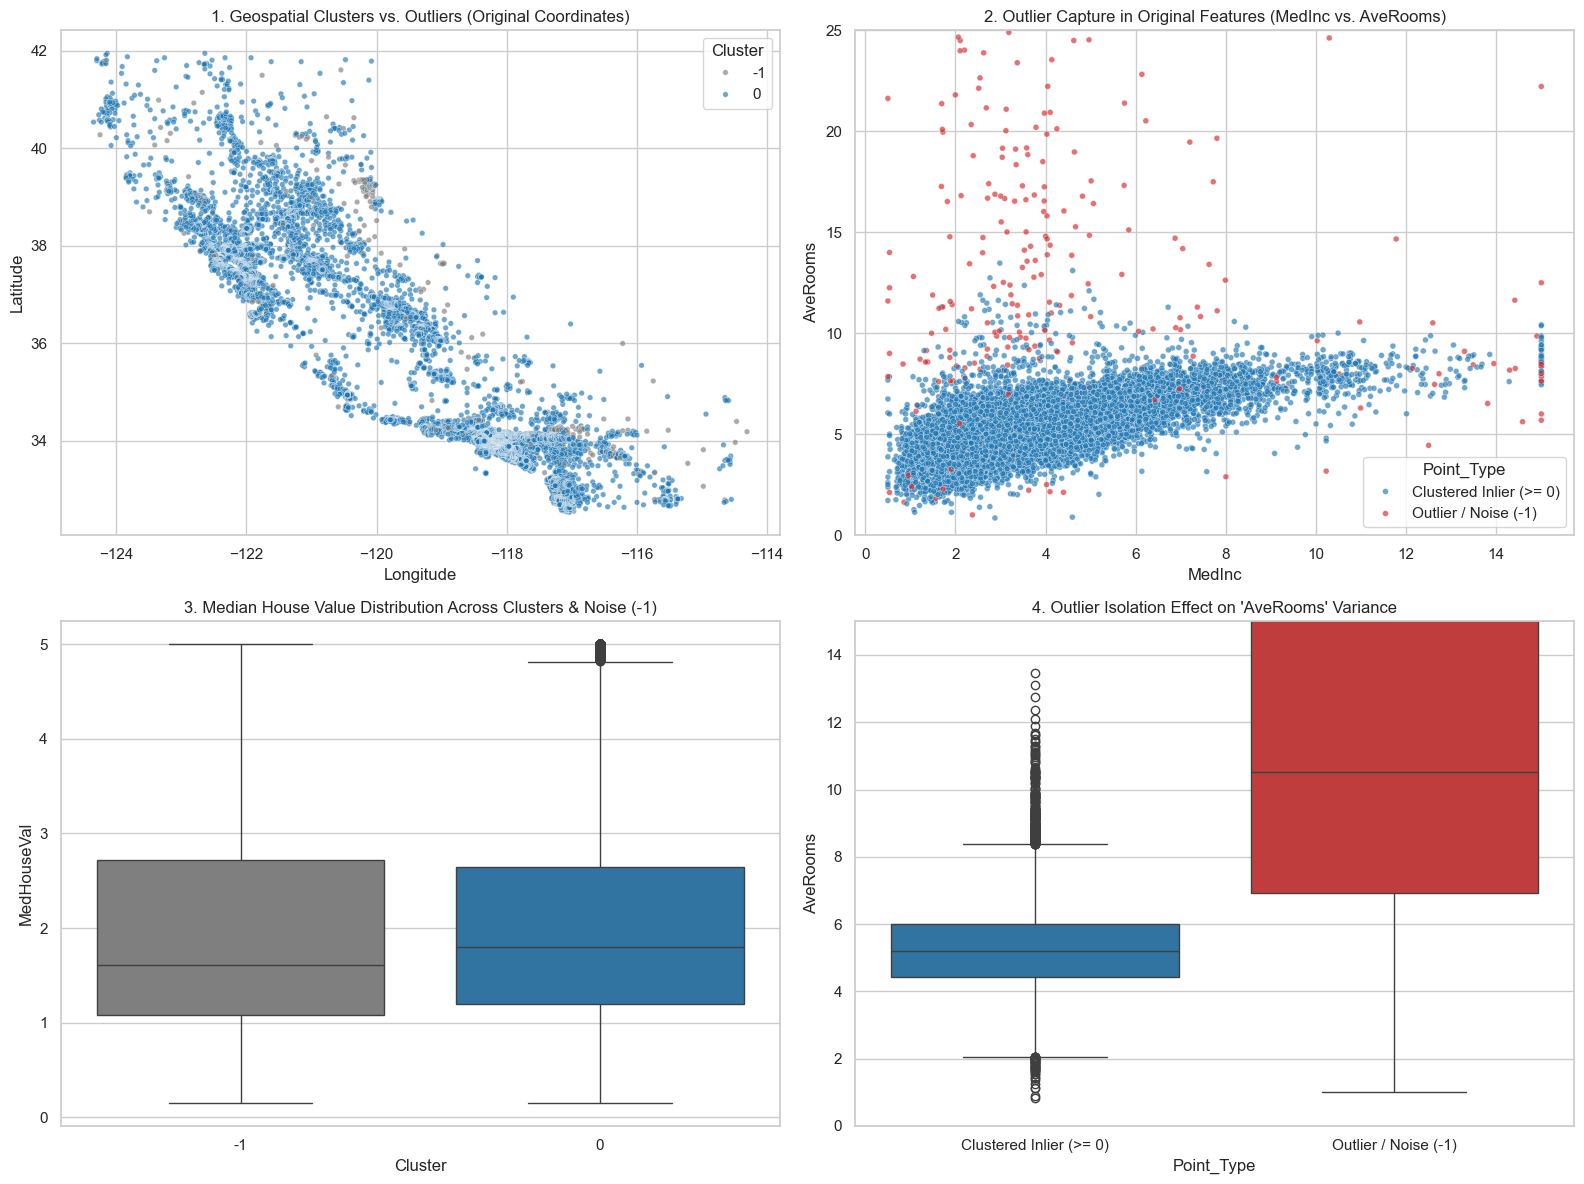

In [9]:
# Build dynamic color mapping so Noise (-1) is always distinct grey
unique_clusters = sorted(df['Cluster'].unique())
n_valid_clusters = len([c for c in unique_clusters if c != -1])
palette_colors = sns.color_palette("tab10", n_colors=max(1, n_valid_clusters))

cluster_palette = {}
color_idx = 0
for c in unique_clusters:
    if c == -1:
        cluster_palette[c] = "#7f7f7f"  # Grey for Noise/Outliers
    else:
        cluster_palette[c] = palette_colors[color_idx % len(palette_colors)]
        color_idx += 1

point_palette = {
    'Clustered Inlier (>= 0)': '#1f77b4',
    'Outlier / Noise (-1)': '#d62728'
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Geospatial Cluster Assignment (Original Longitude vs. Latitude)
sns.scatterplot(
    data=df, x='Longitude', y='Latitude', hue='Cluster',
    palette=cluster_palette, alpha=0.65, s=16, ax=axes[0, 0]
)
axes[0, 0].set_title("1. Geospatial Clusters vs. Outliers (Original Coordinates)")

# Plot 2: Structural & Economic Outlier Isolation (MedInc vs. AveRooms)
sns.scatterplot(
    data=df, x='MedInc', y='AveRooms', hue='Point_Type',
    palette=point_palette, alpha=0.65, s=18, ax=axes[0, 1]
)
axes[0, 1].set_ylim(0, 25)
axes[0, 1].set_title("2. Outlier Capture in Original Features (MedInc vs. AveRooms)")

# Plot 3: House Value Distribution per Cluster (Version-Safe Boxplot)
sns.boxplot(
    data=df, x='Cluster', y='MedHouseVal', hue='Cluster',
    palette=cluster_palette, dodge=False, ax=axes[1, 0]
)
if axes[1, 0].get_legend() is not None:
    axes[1, 0].get_legend().remove()
axes[1, 0].set_title("3. Median House Value Distribution Across Clusters & Noise (-1)")

# Plot 4: Variance Reduction in AveRooms (Inliers vs. Captured Outliers)
sns.boxplot(
    data=df, x='Point_Type', y='AveRooms', hue='Point_Type',
    palette=point_palette, dodge=False, ax=axes[1, 1]
)
if axes[1, 1].get_legend() is not None:
    axes[1, 1].get_legend().remove()
axes[1, 1].set_ylim(0, 15)
axes[1, 1].set_title("4. Outlier Isolation Effect on 'AveRooms' Variance")

plt.tight_layout()
plt.show()

In [11]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN


housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X = df[features].values

# Fit scaler and DBSCAN model
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

min_pts = 2 * len(features)  # 16
eps_optimal = 1.15

dbscan = DBSCAN(eps=eps_optimal, min_samples=min_pts, metric='euclidean', n_jobs=-1)
dbscan.fit(X_scaled)

dbscan.labels_

array([0, 0, 0, ..., 0, 0, 0], shape=(20640,))

In [12]:
# ==============================================================================
# 2. DEFINE YOUR MANUAL INPUT RECORD(S)
# ==============================================================================
# Provide values matching the 8 feature columns in order:
# ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
manual_data = [
    [8.3252, 41.0, 6.984, 1.023, 322.0, 2.555, 37.88, -122.23],  # Example 1: Typical high-income urban core
    [15.5000, 5.0, 14.250, 1.100, 45.0, 1.200, 41.50, -120.00]   # Example 2: Extreme outlier (isolated location/rooms)
]

manual_df = pd.DataFrame(manual_data, columns=features)


In [13]:

# ==============================================================================
# 3. PREDICT / ASSIGN CLUSTER FOR MANUAL INPUT
# ==============================================================================
# Step A: Scale manual data using the exact training scaler
X_manual_scaled = scaler.transform(manual_df[features])

# Step B: DBSCAN is a transductive clustering algorithm (it doesn't have a direct .predict() method).
# To classify new points, we check if they fall within ε of a Core Point using NearestNeighbors.
neighbors = NearestNeighbors(n_neighbors=1, metric='euclidean').fit(X_scaled)
distances, indices = neighbors.kneighbors(X_manual_scaled)

predicted_clusters = []
for i, dist in enumerate(distances):
    nearest_train_idx = indices[i][0]
    # If the closest training point is within distance ε, assign its cluster. Otherwise, classify as Noise (-1).
    if dist[0] <= eps_optimal:
        cluster_id = dbscan.labels_[nearest_train_idx]
        predicted_clusters.append(cluster_id if cluster_id != -1 else -1)
    else:
        predicted_clusters.append(-1)  # Isolated outlier

manual_df['Predicted_Cluster'] = predicted_clusters
manual_df['Classification'] = np.where(
    manual_df['Predicted_Cluster'] == -1, 
    'Outlier / Noise (-1)', 
    'Clustered Inlier (>= 0)'
)

print("\nPREDICTION RESULTS FOR MANUAL INPUT:")
print("=" * 70)
print(manual_df[['MedInc', 'AveRooms', 'Latitude', 'Longitude', 'Predicted_Cluster', 'Classification']])


PREDICTION RESULTS FOR MANUAL INPUT:
    MedInc  AveRooms  Latitude  Longitude  Predicted_Cluster  \
0   8.3252     6.984     37.88    -122.23                  0   
1  15.5000    14.250     41.50    -120.00                 -1   

            Classification  
0  Clustered Inlier (>= 0)  
1     Outlier / Noise (-1)  


d:\ANN_PTROJECT\penve\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [14]:
from sklearn.cluster import  DBSCAN
import numpy as np
import matplotlib.pyplot as plt





In [37]:
x=np.array([[1,2],[1,1],[1.5,1.5],[5,1],[5,2],[9,8],[9,5]])

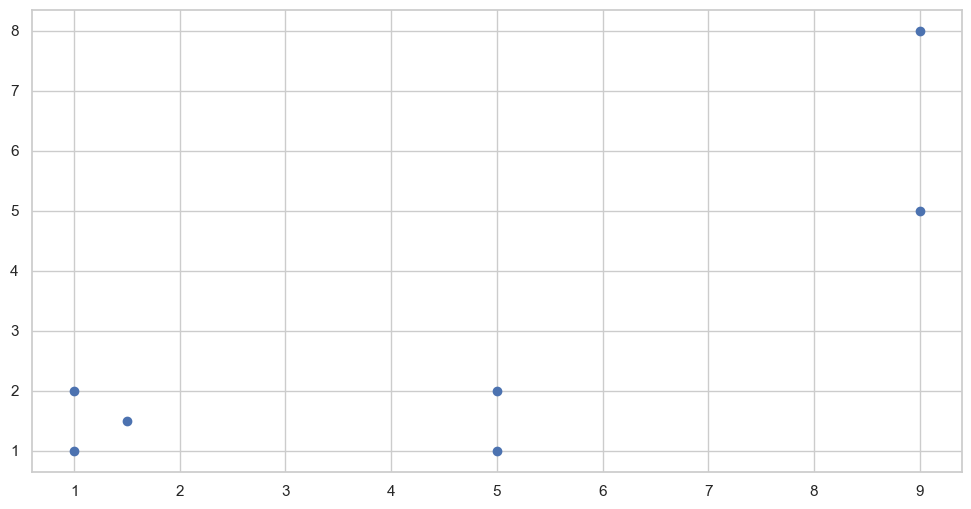

In [38]:
plt.scatter(x[:,0],x[:,1])
plt.show()

In [39]:
model=DBSCAN(eps=1,min_samples=2)

In [40]:
model.fit(x)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",1
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",2
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [41]:
model.labels_

array([ 0,  0,  0,  1,  1, -1, -1])

In [ ]:
model.fit(x)

point = np.array([[1, 0]])
core_labels = model.labels_[model.core_sample_indices_]
distances_to_core = np.linalg.norm(model.components_ - point, axis=1)

nearby = np.flatnonzero(distances_to_core <= model.eps)
predicted_label = core_labels[nearby[0]] if len(nearby) else -1
predicted_label

array([-1])

In [52]:
model.fit_predict(np.array([[1,1.2]]))

array([-1])